# SmartFactory — Part A: Sensor Classification

## 1. Environment and Reproducibility

In [1]:
from pathlib import Path
from copy import deepcopy
from time import perf_counter
import hashlib
import random
import platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay, classification_report, precision_recall_curve,
    matthews_corrcoef, log_loss,
)

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ROOT = Path.cwd()
if not (ROOT / 'data').is_dir():
    raise FileNotFoundError('The notebook and its data folder must share a directory.')
OUT = ROOT / 'outputs' / 'part_a'
MODELS = ROOT / 'models'
OUT.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', palette='colorblind', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 180, 'axes.spines.top': False,
                      'axes.spines.right': False, 'figure.constrained_layout.use': True})

In [4]:
environment = pd.Series({
    'Python': platform.python_version(), 'Device': str(DEVICE),
    'Processor': platform.machine(), 'Torch threads': torch.get_num_threads(),
    **{p: metadata.version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'torch']},
}, name='Executed environment')
display(environment.to_frame())
environment.to_csv(OUT / 'environment.csv')

,Executed environment
Python,3.12.14
Device,cpu
Processor,x86_64
Torch threads,4
numpy,2.3.5
pandas,2.2.3
scikit-learn,1.8.0
torch,2.14.1


In [5]:
def save_figure(name):
    plt.savefig(OUT / f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close()

def sync_device():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()

In [6]:
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA

## 2. Dataset and Modelling Scope

In [7]:
data_path = ROOT / 'data' / 'ai4i2020.csv'
raw = pd.read_csv(data_path)
display(raw.head())
scope = pd.Series({
    'Dataset': 'UCI AI4I 2020 — 10,000 synthetic manufacturing observations',
    'Source': 'https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset',
    'Licence': 'CC BY 4.0; DOI: 10.24432/C5HS5C',
    'Target': 'Machine failure: 1 = failure, 0 = no machine failure',
    'Suitability': 'Manufacturing sensor failure proxy; not a direct finished-product QC label',
    'Classical choice': 'Random Forest captures nonlinear interactions with modest preprocessing',
    'Neural choice': 'Small ReLU MLP learns nonlinear boundaries through backpropagation',
    'Comparison limit': 'Sensor rows and casting images are unrelated units; no paired fusion',
    'Generalisation': 'Synthetic rules and random row splits do not establish future-factory performance',
    'SHA256': hashlib.sha256(data_path.read_bytes()).hexdigest(),
}, name='Dataset and design')
display(scope.to_frame())
scope.to_csv(OUT / 'dataset_scope.csv')

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


,Dataset and design
Dataset,"UCI AI4I 2020 — 10,000 synthetic manufacturing..."
Source,https://archive.ics.uci.edu/dataset/601/ai4i+2...
Licence,CC BY 4.0; DOI: 10.24432/C5HS5C
Target,"Machine failure: 1 = failure, 0 = no machine f..."
Suitability,Manufacturing sensor failure proxy; not a dire...
Classical choice,Random Forest captures nonlinear interactions ...
Neural choice,Small ReLU MLP learns nonlinear boundaries thr...
Comparison limit,Sensor rows and casting images are unrelated u...
Generalisation,Synthetic rules and random row splits do not e...
SHA256,dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1...


In [8]:
audit = pd.DataFrame({'dtype': raw.dtypes.astype(str),
                      'missing': raw.isna().sum(), 'unique': raw.nunique()})
display(audit)
display(pd.Series({'rows': len(raw), 'columns': raw.shape[1],
                   'duplicate_rows': raw.duplicated().sum(),
                   'failure_rate': raw['Machine failure'].mean()}).to_frame('Audit'))
assert raw['Machine failure'].isin([0, 1]).all()
assert raw['UDI'].is_unique
assert raw['Machine failure'].value_counts().min() >= 300

,dtype,missing,unique
UDI,int64,0,10000
Product ID,object,0,10000
Type,object,0,3
Air temperature [K],float64,0,93
Process temperature [K],float64,0,82
Rotational speed [rpm],int64,0,941
Torque [Nm],float64,0,577
Tool wear [min],int64,0,246
Machine failure,int64,0,2
TWF,int64,0,2


,Audit
rows,10000.0000
columns,14.0000
duplicate_rows,0.0000
failure_rate,0.0339


## 3. Feature Definitions and Leakage Control

In [9]:
excluded = ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
display(pd.DataFrame({
    'excluded_columns': ['UDI / Product ID', 'TWF / HDF / PWF / OSF / RNF'],
    'reason': ['Identifiers can encode order or serial-number shortcuts',
               'Failure-mode flags reveal the outcome and would leak target information'],
}))

def make_features(frame):
    features = frame.drop(columns=excluded + ['Machine failure'], errors='ignore').copy()
    features['Temperature gap [K]'] = (
        features['Process temperature [K]'] - features['Air temperature [K]'])
    features['Mechanical power [W]'] = (
        features['Torque [Nm]'] * features['Rotational speed [rpm]'] * 2 * np.pi / 60)
    features['Wear torque interaction'] = features['Tool wear [min]'] * features['Torque [Nm]']
    return features.replace([np.inf, -np.inf], np.nan)

X = make_features(raw)
y = raw['Machine failure'].astype(int)
assert not set(excluded).intersection(X.columns)
assert not X.duplicated().any(), 'Identical predictor rows require grouped splitting.'

,excluded_columns,reason
0,UDI / Product ID,Identifiers can encode order or serial-number ...
1,TWF / HDF / PWF / OSF / RNF,Failure-mode flags reveal the outcome and woul...


## 4. Fixed Train, Validation and Test Partitions

In [10]:
train_idx, holdout_idx = train_test_split(
    np.arange(len(raw)), test_size=0.40, stratify=y, random_state=SEED)
val_idx, test_idx = train_test_split(
    holdout_idx, test_size=0.50, stratify=y.iloc[holdout_idx], random_state=SEED)
X_train, X_val, X_test = [X.iloc[idx].copy() for idx in [train_idx, val_idx, test_idx]]
y_train, y_val, y_test = [y.iloc[idx].to_numpy() for idx in [train_idx, val_idx, test_idx]]
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx)
            or set(val_idx) & set(test_idx))
split_table = pd.DataFrame([
    {'split': name, 'rows': len(idx), 'pass': int((y.iloc[idx] == 0).sum()),
     'fail': int((y.iloc[idx] == 1).sum()), 'failure_rate': y.iloc[idx].mean()}
    for name, idx in [('train', train_idx), ('validation', val_idx), ('test', test_idx)]])
display(split_table)
split_table.to_csv(OUT / 'split_summary.csv', index=False)
split_assignment = pd.concat([
    pd.DataFrame({'UDI': raw.iloc[idx]['UDI'], 'split': name})
    for name, idx in [('train', train_idx), ('validation', val_idx), ('test', test_idx)]])
split_assignment.sort_values('UDI').to_csv(OUT / 'sensor_split.csv', index=False)

,split,rows,pass,fail,failure_rate
0,train,6000,5797,203,0.033833
1,validation,2000,1932,68,0.034000
2,test,2000,1932,68,0.034000


## 5. Exploratory Analysis of the Training Partition

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Type,6000,3,L,3636,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],6000.0,NaN,NaN,NaN,300.019783,2.004329,295.3,298.3,300.1,301.5,304.5
Process temperature [K],6000.0,NaN,NaN,NaN,310.012383,1.479536,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],6000.0,NaN,NaN,NaN,1538.8695,180.530086,1168.0,1422.0,1503.0,1614.0,2886.0
Torque [Nm],6000.0,NaN,NaN,NaN,40.034067,10.035769,3.8,33.2,40.1,46.9,76.6
Tool wear [min],6000.0,NaN,NaN,NaN,107.492833,63.571628,0.0,52.0,107.0,162.0,253.0
Temperature gap [K],6000.0,NaN,NaN,NaN,9.9926,1.004865,7.6,9.3,9.8,11.0,12.1
Mechanical power [W],6000.0,NaN,NaN,NaN,6285.675712,1073.137522,1148.44061,5555.576741,6271.844158,7018.365112,10469.923005
Wear torque interaction,6000.0,NaN,NaN,NaN,4304.505417,2828.078876,0.0,1923.0,4002.0,6283.6,16497.0


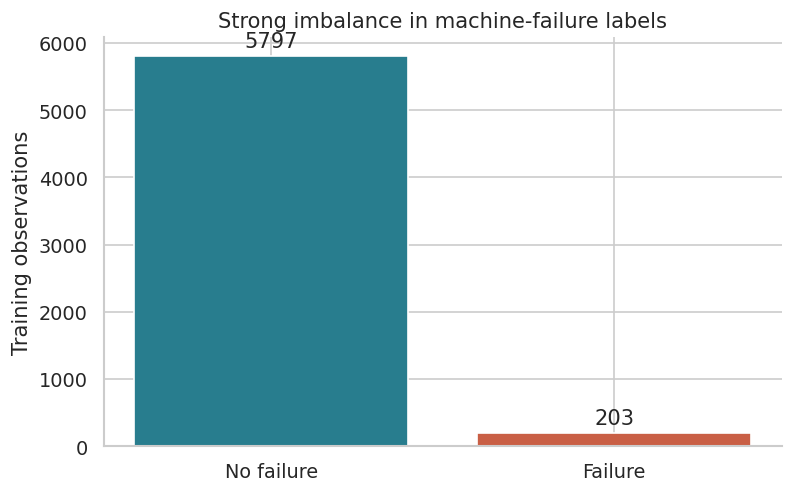

In [11]:
display(X_train.describe(include='all').T)
fig, ax = plt.subplots(figsize=(6.5, 4))
counts = pd.Series(y_train).value_counts().sort_index()
ax.bar(['No failure', 'Failure'], counts, color=['#287d8e', '#c95f45'])
ax.bar_label(ax.containers[0], padding=3)
ax.set(ylabel='Training observations', title='Strong imbalance in machine-failure labels')
save_figure('01_class_distribution')

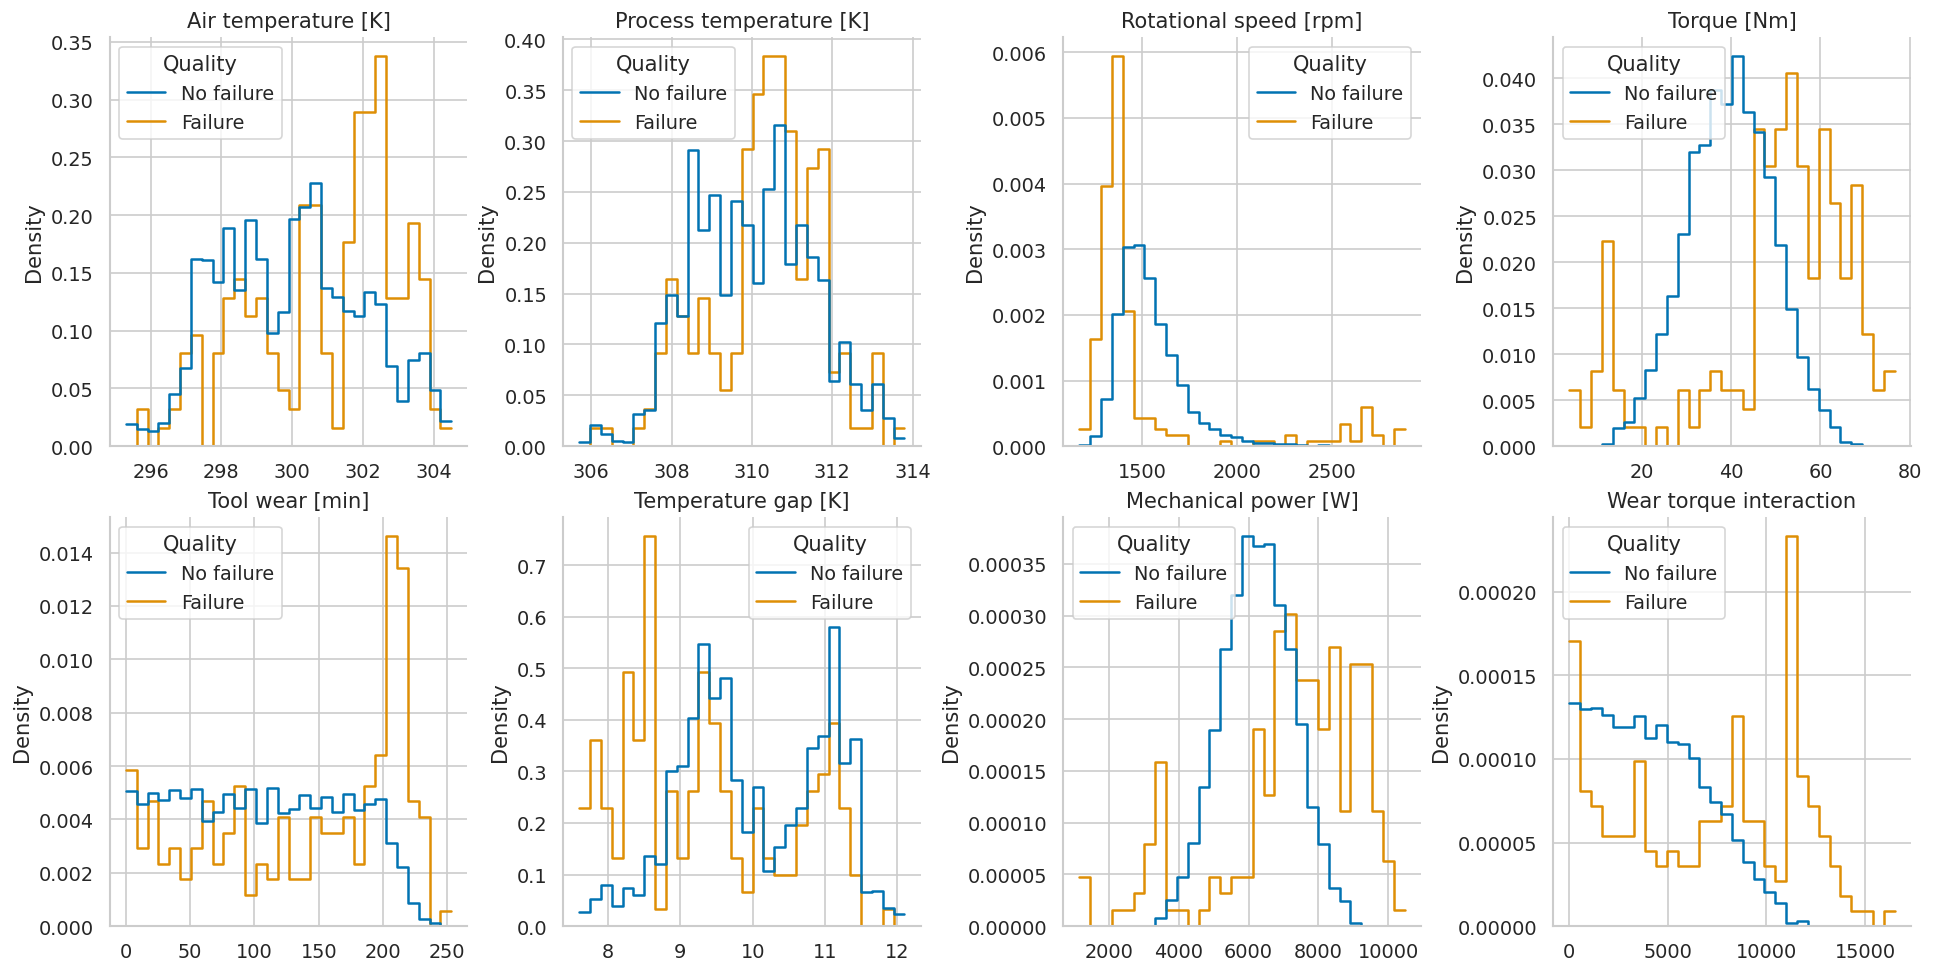

In [12]:
numeric_columns = X.select_dtypes(include='number').columns.tolist()
plot_frame = X_train.assign(Quality=np.where(y_train == 1, 'Failure', 'No failure'))
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, column in zip(axes.ravel(), numeric_columns):
    sns.histplot(data=plot_frame, x=column, hue='Quality', stat='density',
                 common_norm=False, element='step', fill=False, bins=30, ax=ax)
    ax.set_title(column)
    ax.set_xlabel('')
save_figure('02_sensor_distributions')

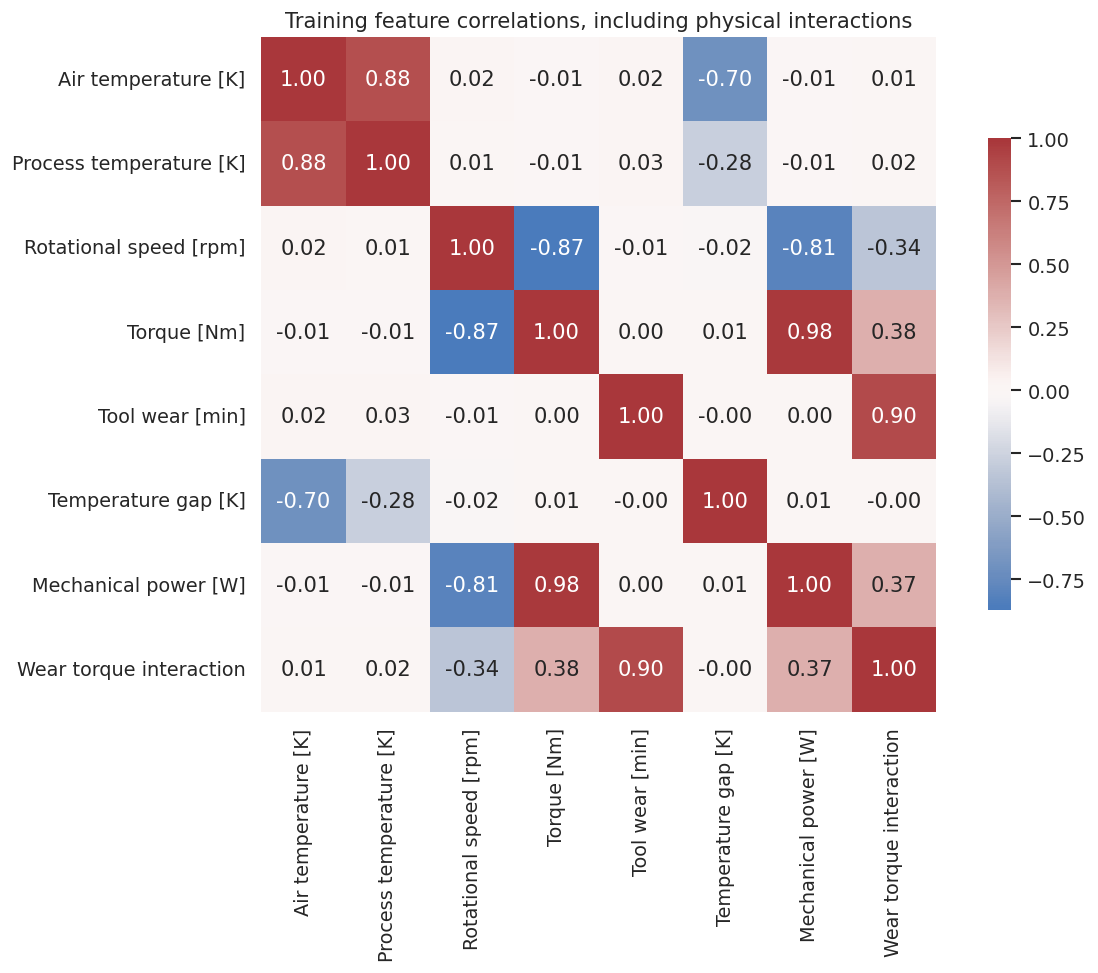

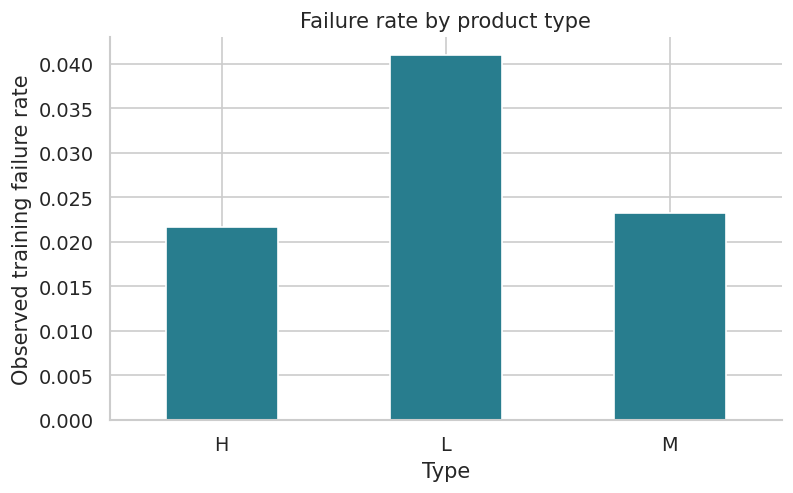

In [13]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(X_train[numeric_columns].corr(), cmap='vlag', center=0, annot=True,
            fmt='.2f', square=True, ax=ax, cbar_kws={'shrink': 0.7})
ax.set_title('Training feature correlations, including physical interactions')
save_figure('03_sensor_correlations')
fig, ax = plt.subplots(figsize=(6.5, 4))
rates = plot_frame.groupby('Type')['Quality'].apply(lambda x: (x == 'Failure').mean())
rates.plot.bar(ax=ax, color='#287d8e', rot=0)
ax.set(ylabel='Observed training failure rate', title='Failure rate by product type')
save_figure('04_type_failure_rate')

## 6. Training-Only Preprocessing and PCA Diagnostics

In [14]:
numeric_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])
categorical_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_columns),
    ('category', categorical_pipeline, ['Type']),
])
train_array = preprocessor.fit_transform(X_train).astype('float32')
val_array = preprocessor.transform(X_val).astype('float32')
test_array = preprocessor.transform(X_test).astype('float32')
feature_names = preprocessor.get_feature_names_out()
assert np.isfinite(train_array).all() and np.isfinite(test_array).all()
display(pd.Series({'training_shape': train_array.shape, 'validation_shape': val_array.shape,
                   'test_shape': test_array.shape, 'fit_partition': 'Training only'}).to_frame())

,0
training_shape,"(6000, 11)"
validation_shape,"(2000, 11)"
test_shape,"(2000, 11)"
fit_partition,Training only


PCA is diagnostic only; both models retain the same interpretable input features.


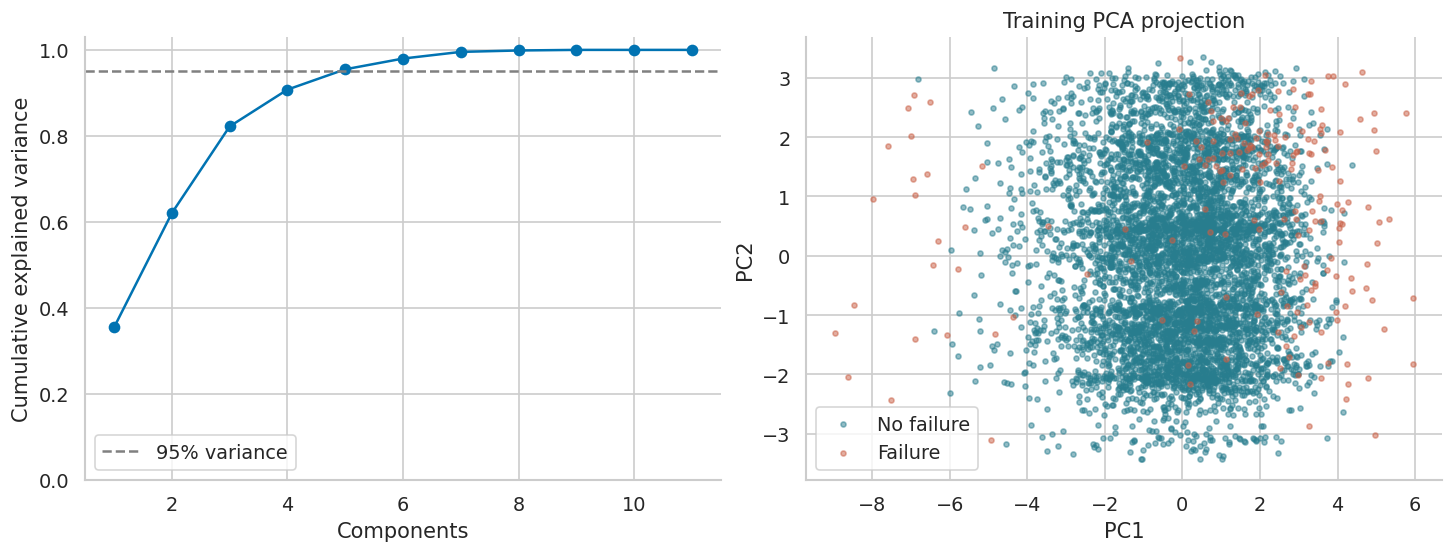

In [15]:
pca = PCA(random_state=SEED).fit(train_array)
scores = pca.transform(train_array)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(np.arange(1, len(pca.explained_variance_ratio_) + 1),
             np.cumsum(pca.explained_variance_ratio_), marker='o')
axes[0].axhline(0.95, ls='--', color='gray', label='95% variance')
axes[0].set(xlabel='Components', ylabel='Cumulative explained variance', ylim=(0, 1.03))
axes[0].legend()
for label, name, colour in [(0, 'No failure', '#287d8e'), (1, 'Failure', '#c95f45')]:
    mask = y_train == label
    axes[1].scatter(scores[mask, 0], scores[mask, 1], s=9, alpha=0.5,
                    label=name, color=colour)
axes[1].set(xlabel='PC1', ylabel='PC2', title='Training PCA projection')
axes[1].legend()
save_figure('05_pca_diagnostic')
print('PCA is diagnostic only; both models retain the same interpretable input features.')

## 7. Random Forest: Validation-Based Configuration Selection

In [16]:
forest_grid = [
    {'max_depth': depth, 'min_samples_leaf': leaf}
    for depth in [10, None] for leaf in [1, 3]
]
forest_runs, forests = [], []
search_start = perf_counter()
for config in forest_grid:
    forest = RandomForestClassifier(
        n_estimators=250, class_weight='balanced_subsample',
        max_features=0.8, n_jobs=4, random_state=SEED, **config)
    started = perf_counter()
    forest.fit(train_array, y_train)
    elapsed = perf_counter() - started
    probability = forest.predict_proba(val_array)[:, 1]
    forest_runs.append({**config, 'validation_ap': average_precision_score(y_val, probability),
                        'fit_seconds': elapsed})
    forests.append(forest)
forest_search_seconds = perf_counter() - search_start
forest_selection = pd.DataFrame(forest_runs)
best_forest_index = int(forest_selection['validation_ap'].to_numpy().argmax())
rf = forests[best_forest_index]
rf_fit_seconds = forest_runs[best_forest_index]['fit_seconds']
display(forest_selection.sort_values('validation_ap', ascending=False))
forest_selection.to_csv(OUT / 'forest_validation_search.csv', index=False)

,max_depth,min_samples_leaf,validation_ap,fit_seconds
1,10.0,3,0.856102,1.046298
3,NaN,3,0.853610,0.990241
2,NaN,1,0.845702,1.023518
0,10.0,1,0.833939,1.004477


## 8. Mandatory Feed-Forward Network

### 8.1. Architecture and Weighted Binary Cross-Entropy

In [17]:
class SensorMLP(nn.Module):
    def __init__(self, inputs):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(inputs, 32), nn.ReLU(), nn.Dropout(0.15),
            nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.network(x).squeeze(1)

torch.manual_seed(SEED)
mlp = SensorMLP(train_array.shape[1]).to(DEVICE)
positive_weight = float((y_train == 0).sum() / (y_train == 1).sum())
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(positive_weight, device=DEVICE))
optimizer = torch.optim.AdamW(mlp.parameters(), lr=0.001, weight_decay=0.001)
display(mlp)
print(f'Trainable parameters: {sum(p.numel() for p in mlp.parameters()):,}')
print(f'Positive-class loss weight (training labels only): {positive_weight:.3f}')

Trainable parameters: 929
Positive-class loss weight (training labels only): 28.557


SensorMLP(
  (network): Sequential(
    (0): Linear(in_features=11, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.15, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Linear(in_features=16, out_features=1, bias=True)
  )
)

In [18]:
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(torch.from_numpy(train_array),
                          torch.tensor(y_train, dtype=torch.float32)),
                          batch_size=128, shuffle=True, generator=generator)
val_tensor = torch.from_numpy(val_array).to(DEVICE)
val_target = torch.tensor(y_val, dtype=torch.float32, device=DEVICE)

@torch.inference_mode()
def neural_probabilities(model, array):
    model.eval()
    tensor = torch.as_tensor(array, dtype=torch.float32, device=DEVICE)
    return model(tensor).sigmoid().cpu().numpy()

### 8.2. Backpropagation, Validation and Early Stopping

In [19]:
history, best_ap, best_epoch, stale = [], -np.inf, 0, 0
sync_device()
started = perf_counter()
for epoch in range(1, 151):
    mlp.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(mlp(xb), yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(yb)
    mlp.eval()
    with torch.no_grad():
        logits = mlp(val_tensor)
        val_loss = criterion(logits, val_target).item()
        val_probability = logits.sigmoid().cpu().numpy()
    ap = average_precision_score(y_val, val_probability)
    history.append({'epoch': epoch, 'train_loss': total_loss / len(y_train),
                    'validation_loss': val_loss, 'validation_ap': ap})
    if ap > best_ap + 0.0001:
        best_ap, best_epoch, stale = ap, epoch, 0
        best_state = deepcopy(mlp.state_dict())
    else:
        stale += 1
    if stale >= 25:
        break
sync_device()
mlp_fit_seconds = perf_counter() - started
mlp.load_state_dict(best_state)
mlp_history = pd.DataFrame(history)
print(f'Best epoch: {best_epoch}; epochs run: {len(history)}; training: {mlp_fit_seconds:.2f} s')
mlp_history.to_csv(OUT / 'mlp_training_history.csv', index=False)

Best epoch: 138; epochs run: 150; training: 8.58 s


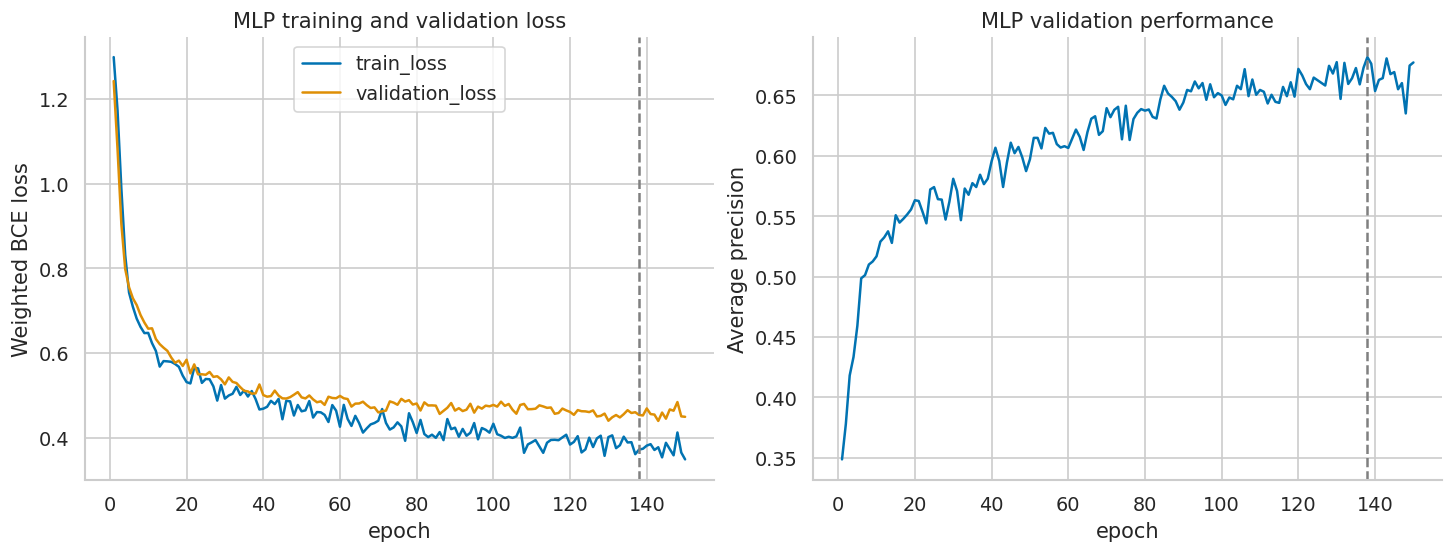

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
mlp_history.plot(x='epoch', y=['train_loss', 'validation_loss'], ax=axes[0])
mlp_history.plot(x='epoch', y='validation_ap', ax=axes[1], legend=False)
for ax in axes:
    ax.axvline(best_epoch, ls='--', color='gray')
axes[0].set(ylabel='Weighted BCE loss', title='MLP training and validation loss')
axes[1].set(ylabel='Average precision', title='MLP validation performance')
save_figure('06_mlp_learning_curves')

## 9. Validation-Only Decision Thresholds

In [21]:
def choose_threshold(y_true, probabilities):
    # Validation-only F2 selection weights recall more strongly than precision.
    precision, recall, thresholds = precision_recall_curve(y_true, probabilities)
    scores = 5 * precision[:-1] * recall[:-1] / (
        4 * precision[:-1] + recall[:-1] + 1e-12)
    best = np.flatnonzero(np.isclose(scores, scores.max()))[-1]
    return float(thresholds[best])

def metrics_row(name, truth, probability, threshold):
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(truth, prediction, labels=[0, 1]).ravel()
    return {'model': name, 'threshold': threshold,
            'accuracy': accuracy_score(truth, prediction),
            'balanced_accuracy': balanced_accuracy_score(truth, prediction),
            'precision_fail': precision_score(truth, prediction, zero_division=0),
            'recall_fail': recall_score(truth, prediction, zero_division=0),
            'f1_fail': f1_score(truth, prediction, zero_division=0),
            'f2_fail': fbeta_score(truth, prediction, beta=2, zero_division=0),
            'average_precision': average_precision_score(truth, probability),
            'roc_auc': roc_auc_score(truth, probability),
            'mcc': matthews_corrcoef(truth, prediction),
            'specificity': tn / (tn + fp), 'missed_failures': int(fn),
            'false_alarms': int(fp), 'true_failures': int(tp), 'true_pass': int(tn)}

In [22]:
def bootstrap_intervals(truth, probability, threshold, repeats=400):
    truth = np.asarray(truth)
    rng = np.random.default_rng(SEED)
    groups = [np.flatnonzero(truth == label) for label in [0, 1]]
    values = []
    for _ in range(repeats):
        idx = np.concatenate([rng.choice(g, len(g), replace=True) for g in groups])
        pred = probability[idx] >= threshold
        values.append([average_precision_score(truth[idx], probability[idx]),
                       recall_score(truth[idx], pred),
                       fbeta_score(truth[idx], pred, beta=2, zero_division=0)])
    bounds = np.quantile(values, [0.025, 0.975], axis=0)
    return pd.DataFrame(bounds.T, columns=['lower_95', 'upper_95'],
                        index=['average_precision', 'recall_fail', 'f2_fail'])

In [23]:
validation_probabilities = {'Random Forest': rf.predict_proba(val_array)[:, 1],
                            'Feed-forward MLP': neural_probabilities(mlp, val_array)}
thresholds = {name: choose_threshold(y_val, prob)
              for name, prob in validation_probabilities.items()}
validation_results = pd.DataFrame([
    metrics_row(name, y_val, prob, thresholds[name])
    for name, prob in validation_probabilities.items()])
display(validation_results.round(4))
validation_results.to_csv(OUT / 'validation_metrics.csv', index=False)
print('Thresholds are frozen before held-out test evaluation; F2 favours catching failures.')

Thresholds are frozen before held-out test evaluation; F2 favours catching failures.


,model,threshold,accuracy,balanced_accuracy,precision_fail,recall_fail,f1_fail,f2_fail,average_precision,roc_auc,mcc,specificity,missed_failures,false_alarms,true_failures,true_pass
0,Random Forest,0.5432,0.9915,0.8963,0.9474,0.7941,0.8640,0.8207,0.8561,0.9653,0.8632,0.9984,14,3,54,1929
1,Feed-forward MLP,0.8572,0.9710,0.8573,0.5556,0.7353,0.6329,0.6906,0.6817,0.9685,0.6247,0.9793,18,40,50,1892


## 10. Held-Out Test Evaluation on Identical Sensor Rows

In [24]:
test_probabilities = {'Random Forest': rf.predict_proba(test_array)[:, 1],
                      'Feed-forward MLP': neural_probabilities(mlp, test_array)}
test_results = pd.DataFrame([
    metrics_row(name, y_test, probability, thresholds[name])
    for name, probability in test_probabilities.items()])
display(test_results.round(4))
test_results.to_csv(OUT / 'test_metrics.csv', index=False)
baseline = metrics_row('Always no failure', y_test, np.zeros(len(y_test)), 0.5)
display(pd.Series(baseline).to_frame('Imbalance baseline'))
prediction_table = pd.DataFrame({'UDI': raw.iloc[test_idx]['UDI'].to_numpy(), 'actual': y_test})
for name, probability in test_probabilities.items():
    prediction_table[f'{name}_probability'] = probability
    prediction_table[f'{name}_prediction'] = (probability >= thresholds[name]).astype(int)
prediction_table.to_csv(OUT / 'test_predictions.csv', index=False)

,model,threshold,accuracy,balanced_accuracy,precision_fail,recall_fail,f1_fail,f2_fail,average_precision,roc_auc,mcc,specificity,missed_failures,false_alarms,true_failures,true_pass
0,Random Forest,0.5432,0.991,0.9102,0.9032,0.8235,0.8615,0.8383,0.8972,0.9842,0.8579,0.9969,12,6,56,1926
1,Feed-forward MLP,0.8572,0.972,0.8862,0.5625,0.7941,0.6585,0.7337,0.7296,0.9747,0.6548,0.9783,14,42,54,1890


,Imbalance baseline
model,Always no failure
threshold,0.5
accuracy,0.966
balanced_accuracy,0.5
precision_fail,0.0
recall_fail,0.0
f1_fail,0.0
f2_fail,0.0
average_precision,0.034
roc_auc,0.5


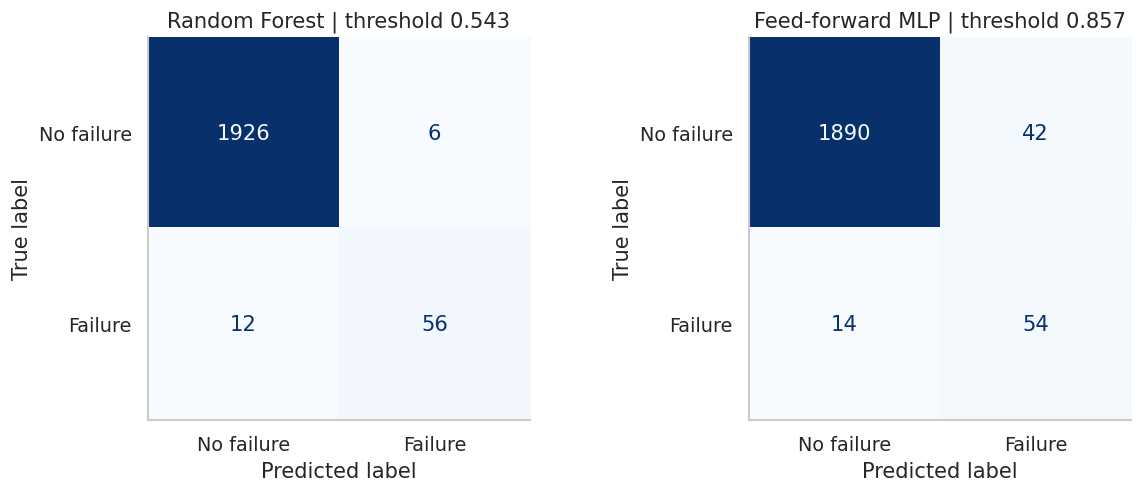

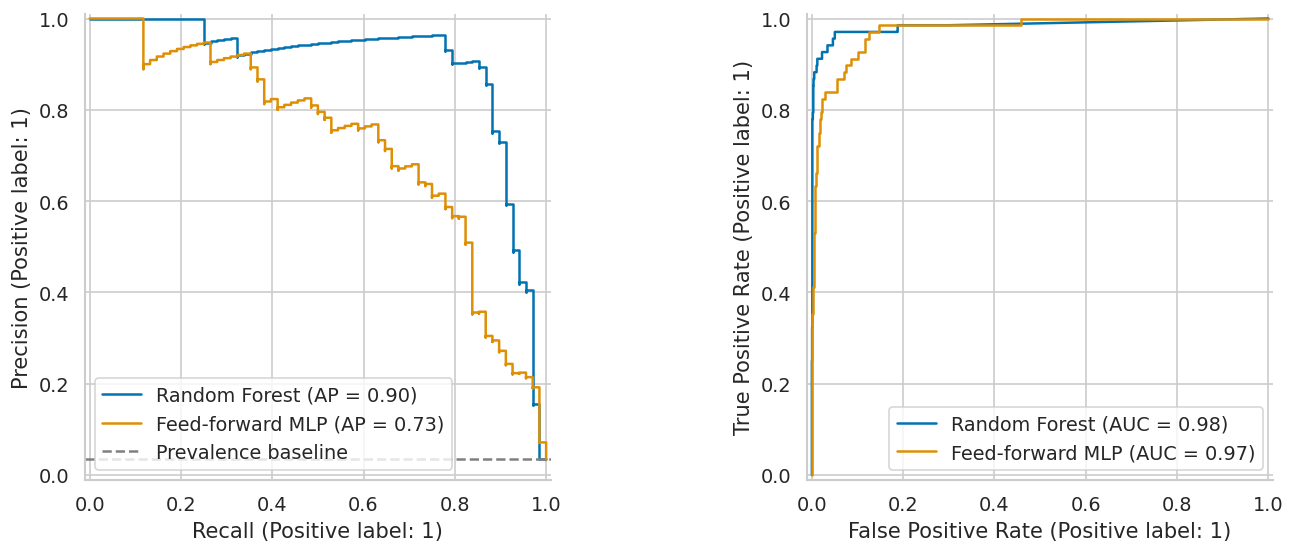

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, probability) in zip(axes, test_probabilities.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, probability >= thresholds[name], display_labels=['No failure', 'Failure'],
        cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f'{name} | threshold {thresholds[name]:.3f}')
    ax.grid(False)
save_figure('07_sensor_confusion_matrices')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, probability in test_probabilities.items():
    PrecisionRecallDisplay.from_predictions(y_test, probability, name=name, ax=axes[0])
    RocCurveDisplay.from_predictions(y_test, probability, name=name, ax=axes[1])
axes[0].axhline(y_test.mean(), ls='--', color='gray', label='Prevalence baseline')
axes[0].legend()
save_figure('08_sensor_pr_roc')

In [26]:
reports, intervals = [], []
for name, probability in test_probabilities.items():
    report = pd.DataFrame(classification_report(
        y_test, probability >= thresholds[name], target_names=['No failure', 'Failure'],
        output_dict=True, zero_division=0)).T
    display(report.round(4))
    report.assign(model=name).to_csv(OUT / f'{name.lower().replace(" ", "_")}_report.csv')
    interval = bootstrap_intervals(y_test, probability, thresholds[name]).assign(model=name)
    intervals.append(interval.rename_axis('metric').reset_index())
interval_table = pd.concat(intervals, ignore_index=True)
display(interval_table.round(4))
interval_table.to_csv(OUT / 'bootstrap_intervals.csv', index=False)
print('95% stratified bootstrap intervals condition on this test split; no retraining uncertainty.')

95% stratified bootstrap intervals condition on this test split; no retraining uncertainty.


,precision,recall,f1-score,support
No failure,0.9938,0.9969,0.9953,1932.000
Failure,0.9032,0.8235,0.8615,68.000
accuracy,0.9910,0.9910,0.9910,0.991
macro avg,0.9485,0.9102,0.9284,2000.000
weighted avg,0.9907,0.9910,0.9908,2000.000


,precision,recall,f1-score,support
No failure,0.9926,0.9783,0.9854,1932.000
Failure,0.5625,0.7941,0.6585,68.000
accuracy,0.9720,0.9720,0.9720,0.972
macro avg,0.7776,0.8862,0.8220,2000.000
weighted avg,0.9780,0.9720,0.9743,2000.000


,metric,lower_95,upper_95,model
0,average_precision,0.8303,0.9608,Random Forest
1,recall_fail,0.7353,0.9118,Random Forest
2,f2_fail,0.7598,0.9132,Random Forest
3,average_precision,0.6345,0.8158,Feed-forward MLP
4,recall_fail,0.6912,0.8824,Feed-forward MLP
5,f2_fail,0.6484,0.8038,Feed-forward MLP


## 11. Interpretability and Failure Analysis

Correlated original and engineered features can share importance; effects are not causal.


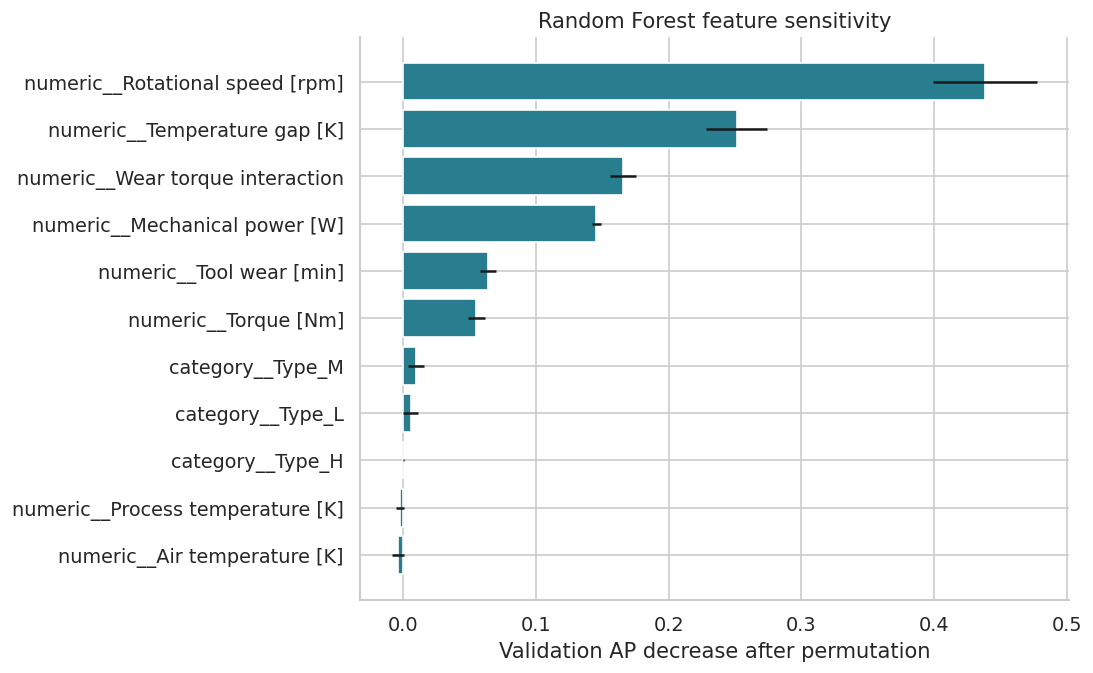

In [27]:
importance = permutation_importance(
    rf, val_array, y_val, scoring='average_precision', n_repeats=8,
    random_state=SEED, n_jobs=1)
importance_table = pd.DataFrame({
    'feature': feature_names, 'mean_ap_drop': importance.importances_mean,
    'std_ap_drop': importance.importances_std}).sort_values('mean_ap_drop')
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(importance_table['feature'], importance_table['mean_ap_drop'],
        xerr=importance_table['std_ap_drop'], color='#287d8e')
ax.set(xlabel='Validation AP decrease after permutation', title='Random Forest feature sensitivity')
save_figure('09_forest_permutation_importance')
importance_table.to_csv(OUT / 'forest_permutation_importance.csv', index=False)
print('Correlated original and engineered features can share importance; effects are not causal.')

In [28]:
best_sensor_name = validation_results.set_index('model')['average_precision'].idxmax()
best_sensor_prob = test_probabilities[best_sensor_name]
errors = X_test.copy().assign(actual=y_test, probability=best_sensor_prob)
errors['prediction'] = (best_sensor_prob >= thresholds[best_sensor_name]).astype(int)
display(errors[errors['actual'] != errors['prediction']].sort_values('probability').head(12))
errors[errors['actual'] != errors['prediction']].to_csv(OUT / 'sensor_errors.csv', index=False)
sensor_interpretation = pd.DataFrame({
    'finding': ['Recommended sensor candidate', 'MLP loss', 'Model selection', 'Evaluation boundary'],
    'interpretation': [best_sensor_name + ' selected by validation AP, subject to a factory pilot',
        'Weighted BCEWithLogitsLoss handles binary targets and scarce failures without resampling test data',
        'Configurations, early stopping and F2 thresholds use validation data only',
        'Machine-failure detection is a proxy; synthetic data, temporal dependence and unmeasured defects limit deployment'],
})
display(sensor_interpretation)
sensor_interpretation.to_csv(OUT / 'sensor_interpretation.csv', index=False)

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature gap [K],Mechanical power [W],Wear torque interaction,actual,probability,prediction
4044,M,301.9,310.9,1419,47.7,20,9.0,7088.092761,954.0,1,0.000000,0
2244,M,299.3,308.4,1542,37.5,203,9.1,6055.419840,7612.5,1,0.004415,0
2166,M,299.6,309.2,1867,23.4,225,9.6,4574.975718,5265.0,1,0.144152,0
7849,M,300.3,311.7,1374,47.9,222,11.4,6892.088795,10633.8,1,0.167777,0
7087,L,300.6,310.3,1648,30.5,217,9.7,5263.633771,6618.5,1,0.227195,0
6256,L,301.0,310.6,1493,37.8,206,9.6,5909.901268,7786.8,1,0.272999,0
586,L,297.6,309.6,1501,49.8,222,12.0,7827.780751,11055.6,1,0.333574,0
4385,L,301.8,309.7,1442,45.3,233,7.9,6840.566676,10554.9,1,0.341958,0
3695,L,302.2,311.3,1530,37.3,207,9.1,5976.251705,7721.1,1,0.409471,0
2502,L,299.2,309.0,1515,48.9,228,9.8,7758.005978,11149.2,1,0.491271,0


,finding,interpretation
0,Recommended sensor candidate,"Random Forest selected by validation AP, subje..."
1,MLP loss,Weighted BCEWithLogitsLoss handles binary targ...
2,Model selection,"Configurations, early stopping and F2 threshol..."
3,Evaluation boundary,Machine-failure detection is a proxy; syntheti...


## 12. Training Cost, Model Persistence and Inference

In [29]:
joblib.dump(preprocessor, MODELS / 'sensor_preprocessor.joblib')
joblib.dump(rf, MODELS / 'random_forest.joblib', compress=3)
torch.save({key: value.cpu() for key, value in mlp.state_dict().items()}, MODELS / 'sensor_mlp.pt')
pd.DataFrame({'feature': X.columns}).to_csv(MODELS / 'sensor_features.csv', index=False)
pd.Series(thresholds, name='threshold').to_csv(MODELS / 'sensor_thresholds.csv')
cost = pd.DataFrame([
    {'model': 'Random Forest', 'training_seconds': rf_fit_seconds,
     'total_search_seconds': forest_search_seconds,
     'parameters_or_nodes': sum(t.tree_.node_count for t in rf.estimators_),
     'capacity_unit': 'tree nodes', 'file_bytes': (MODELS / 'random_forest.joblib').stat().st_size},
    {'model': 'Feed-forward MLP', 'training_seconds': mlp_fit_seconds,
     'total_search_seconds': mlp_fit_seconds,
     'parameters_or_nodes': sum(p.numel() for p in mlp.parameters()),
     'capacity_unit': 'trainable parameters', 'file_bytes': (MODELS / 'sensor_mlp.pt').stat().st_size},
])
display(cost.round(3))
cost.to_csv(OUT / 'model_cost.csv', index=False)

,model,training_seconds,total_search_seconds,parameters_or_nodes,capacity_unit,file_bytes
0,Random Forest,1.046,4.289,26390,tree nodes,774905
1,Feed-forward MLP,8.579,8.579,929,trainable parameters,6649


In [30]:
loaded_preprocessor = joblib.load(MODELS / 'sensor_preprocessor.joblib')
loaded_rf = joblib.load(MODELS / 'random_forest.joblib')
loaded_mlp = SensorMLP(train_array.shape[1]).to(DEVICE)
loaded_mlp.load_state_dict(torch.load(MODELS / 'sensor_mlp.pt', map_location=DEVICE, weights_only=True))
example = raw.iloc[[test_idx[0]]]
example_array = loaded_preprocessor.transform(make_features(example)).astype('float32')
example_probs = {'Random Forest': loaded_rf.predict_proba(example_array)[0, 1],
                 'Feed-forward MLP': neural_probabilities(loaded_mlp, example_array)[0]}
display(pd.DataFrame([{'model': name, 'failure_probability': prob,
                       'predicted_failure': int(prob >= thresholds[name])}
                      for name, prob in example_probs.items()]))
assert np.isclose(example_probs['Random Forest'], test_probabilities['Random Forest'][0])
assert np.isclose(example_probs['Feed-forward MLP'], test_probabilities['Feed-forward MLP'][0])

,model,failure_probability,predicted_failure
0,Random Forest,0.00000,0
1,Feed-forward MLP,0.02622,0
